# Официальный MTEB-бенчмарк embedding-моделей на SciFact

Этот ноутбук использует официальный Python API MTEB. Для каждой модели MTEB сам загружает задачу SciFact, кодирует корпус и запросы, выполняет retrieval и считает стандартные метрики.

Источники:

- [коллекция `mteb/scifact` на Hugging Face](https://huggingface.co/datasets/mteb/scifact);
- [репозиторий MTEB](https://github.com/embeddings-benchmark/mteb);
- [карточка `sentence-transformers/all-MiniLM-L6-v2`](https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2);
- [карточка `BAAI/bge-small-en-v1.5`](https://huggingface.co/BAAI/bge-small-en-v1.5);
- [карточка `intfloat/multilingual-e5-small`](https://huggingface.co/intfloat/multilingual-e5-small).

В отличие от `vector_search.ipynb`, который использует подготовленные локальные матрицы и объединённые train+test qrels, этот notebook следует официальному MTEB-протоколу SciFact и оценивает его `test` split. Так результаты можно сопоставлять с MTEB.

## Установка окружения и кэш

Ноутбук использует то же окружение, что `vector_search.ipynb` и `precompute_embeddings_scifact.ipynb`.

Запускайте notebook из каталога `ozon-llm-1-course/seminars/05-rag-advanced`. MTEB кэширует модели, датасет и результаты, поэтому повторный запуск не обязан заново скачивать всё с нуля.

In [1]:
from pathlib import Path
import gc
import os
import platform
import sys
from time import perf_counter

import matplotlib.pyplot as plt
import pandas as pd
import torch

SEMINAR_DIR = Path.cwd()
MTEB_CACHE_DIR = SEMINAR_DIR / ".mteb-cache"
MTEB_CACHE_DIR.mkdir(exist_ok=True)
os.environ["MTEB_CACHE"] = str(MTEB_CACHE_DIR)
os.environ.setdefault("MPLCONFIGDIR", str(SEMINAR_DIR / ".matplotlib-cache"))

import mteb

if torch.backends.mps.is_available():
    DEVICE = "mps"
elif torch.cuda.is_available():
    DEVICE = "cuda"
else:
    DEVICE = "cpu"

BATCH_SIZE = 64 if DEVICE != "cpu" else 32
print("seminar directory:", SEMINAR_DIR)
print("python:", sys.version.split()[0], platform.platform())
print("torch:", torch.__version__)
print("mteb:", mteb.__version__)
print("device:", DEVICE)
print("batch size:", BATCH_SIZE)


/Users/ivabystrovd/projects/rag_seminar/.venv/faiss311/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


seminar directory: /Users/ivabystrovd/projects/rag_seminar/ozon-llm-1-course/seminars/05-rag-advanced
python: 3.11.15 macOS-26.6.2-arm64-arm-64bit
torch: 2.15.0
mteb: 2.27.1
device: cpu
batch size: 32


## Официальная задача SciFact

`mteb.get_task("SciFact")` возвращает описание задачи, включая основной score и evaluation split. Для этой задачи официальный split — `test`; MTEB сам загрузит нужные корпус, запросы и qrels.

In [2]:
SCIFACT_TASK = mteb.get_task("SciFact")
metadata = SCIFACT_TASK.metadata

task_row = {
    "task": metadata.name,
    "type": metadata.type,
    "dataset": metadata.dataset["path"],
    "eval_splits": ", ".join(metadata.eval_splits),
    "main_score": metadata.main_score,
    "languages": ", ".join(metadata.eval_langs),
    "hf_subsets": ", ".join(metadata.hf_subsets),
}
print(task_row)


{'task': 'SciFact', 'type': 'Retrieval', 'dataset': 'mteb/scifact', 'eval_splits': 'test', 'main_score': 'ndcg_at_10', 'languages': 'eng-Latn', 'hf_subsets': 'default'}


## Конфигурация моделей

Передаём MTEB имена моделей из Hugging Face. На этом этапе ещё ничего не кодируем: модель загружается непосредственно перед своим вызовом `mteb.evaluate`.

In [3]:
MODEL_SPECS = [
    {
        "slug": "all_minilm_l6_v2",
        "name": "sentence-transformers/all-MiniLM-L6-v2",
        "url": "https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2",
    },
    {
        "slug": "bge_small_en_v1_5",
        "name": "BAAI/bge-small-en-v1.5",
        "url": "https://huggingface.co/BAAI/bge-small-en-v1.5",
    },
    {
        "slug": "multilingual_e5_small",
        "name": "intfloat/multilingual-e5-small",
        "url": "https://huggingface.co/intfloat/multilingual-e5-small",
    },
]

for spec in MODEL_SPECS:
    print(spec["slug"], "->", spec["name"])


all_minilm_l6_v2 -> sentence-transformers/all-MiniLM-L6-v2
bge_small_en_v1_5 -> BAAI/bge-small-en-v1.5
multilingual_e5_small -> intfloat/multilingual-e5-small


## Запуск официального MTEB для одной модели

`mteb.get_model` создаёт адаптер модели, а `mteb.evaluate` выполняет полный retrieval-проход: кодирование запросов и корпуса, поиск и подсчёт метрик. Результат сохраняем как `ModelResult`, чтобы затем собрать одну сравнительную таблицу.

In [4]:
def evaluate_model(spec):
    print("loading:", spec["name"])
    model = mteb.get_model(spec["name"], device=DEVICE)
    started = perf_counter()
    result = mteb.evaluate(
        model,
        tasks=[SCIFACT_TASK],
        encode_kwargs={"batch_size": BATCH_SIZE},
        show_progress_bar=True,
    )
    elapsed = perf_counter() - started
    del model
    gc.collect()
    if DEVICE == "mps":
        torch.mps.empty_cache()
    print("elapsed seconds:", round(elapsed, 1))
    return result, elapsed


### `all-MiniLM-L6-v2`

In [5]:
minilm_result, minilm_elapsed = evaluate_model(MODEL_SPECS[0])
minilm_scores = minilm_result.task_results[0].scores["test"][0]
print("NDCG@10:", minilm_scores["ndcg_at_10"])
print("Recall@10:", minilm_scores["recall_at_10"])


loading: sentence-transformers/all-MiniLM-L6-v2


W1111 18:17:22.486000 52298 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 12352.77it/s]

Evaluating tasks:   0%|          | 0/1 [00:00<?, ?it/s]

Evaluating task SciFact:   0%|          | 0/1 [00:00<?, ?it/s]

Evaluating task SciFact: 100%|██████████| 1/1 [00:00<00:00, 304.86it/s]

elapsed seconds: 0.0
NDCG@10: 0.64508
Recall@10: 0.78333


### `bge-small-en-v1.5`

In [6]:
bge_result, bge_elapsed = evaluate_model(MODEL_SPECS[1])
bge_scores = bge_result.task_results[0].scores["test"][0]
print("NDCG@10:", bge_scores["ndcg_at_10"])
print("Recall@10:", bge_scores["recall_at_10"])


loading: BAAI/bge-small-en-v1.5


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 11673.66it/s]

Model prompts specified, these will overwrite the default model prompts. Current prompts will be:
 {'query': 'Represent this sentence for searching relevant passages: ', 'BrightBiologyRetrieval-query': 'Represent this biology post for searching relevant passages: ', 'BrightEarthScienceRetrieval-query': 'Represent this earth_science post for searching relevant passages: ', 'BrightEconomicsRetrieval-query': 'Represent this economics post for searching relevant passages: ', 'BrightPsychologyRetrieval-query': 'Represent this psychology post for searching relevant passages: ', 'BrightRoboticsRetrieval-query': 'Represent this robotics post for searching relevant passages: ', 'BrightStackoverflowRetrieval-query': 'Represent this stackoverflow post for searching relevant passages: ', 'BrightSustainableLivingRetrieval-query': 'Represent this sustainable_living post for searching relevant passages: ', 'BrightPonyRetrieval-query': 'Represent this Pony question for searching relevant passages: ', 

/Users/ivabystrovd/projects/rag_seminar/.venv/faiss311/lib/python3.11/site-packages/mteb/models/sentence_transformer_wrapper.py:434: UserWarning: Model prompts specified, these will overwrite the default model prompts. Current prompts will be:
 {'query': 'Represent this sentence for searching relevant passages: ', 'BrightBiologyRetrieval-query': 'Represent this biology post for searching relevant passages: ', 'BrightEarthScienceRetrieval-query': 'Represent this earth_science post for searching relevant passages: ', 'BrightEconomicsRetrieval-query': 'Represent this economics post for searching relevant passages: ', 'BrightPsychologyRetrieval-query': 'Represent this psychology post for searching relevant passages: ', 'BrightRoboticsRetrieval-query': 'Represent this robotics post for searching relevant passages: ', 'BrightStackoverflowRetrieval-query': 'Represent this stackoverflow post for searching relevant passages: ', 'BrightSustainableLivingRetrieval-query': 'Represent this sustainab

Evaluating tasks:   0%|          | 0/1 [00:00<?, ?it/s]

Evaluating task SciFact:   0%|          | 0/1 [00:00<?, ?it/s]

Evaluating task SciFact: 100%|██████████| 1/1 [00:00<00:00, 864.27it/s]

elapsed seconds: 0.0
NDCG@10: 0.71271
Recall@10: 0.83622


### `multilingual-e5-small`

In [7]:
e5_result, e5_elapsed = evaluate_model(MODEL_SPECS[2])
e5_scores = e5_result.task_results[0].scores["test"][0]
print("NDCG@10:", e5_scores["ndcg_at_10"])
print("Recall@10:", e5_scores["recall_at_10"])


loading: intfloat/multilingual-e5-small


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 9602.70it/s]

Model prompts specified, these will overwrite the default model prompts. Current prompts will be:
 {'query': 'query: ', 'document': 'passage: '}


/Users/ivabystrovd/projects/rag_seminar/.venv/faiss311/lib/python3.11/site-packages/mteb/models/sentence_transformer_wrapper.py:434: UserWarning: Model prompts specified, these will overwrite the default model prompts. Current prompts will be:
 {'query': 'query: ', 'document': 'passage: '}
  self.model_prompts = _resolve_model_prompts(self.model, model_prompts)


Evaluating tasks:   0%|          | 0/1 [00:00<?, ?it/s]

Evaluating task SciFact:   0%|          | 0/1 [00:00<?, ?it/s]

Evaluating task SciFact: 100%|██████████| 1/1 [00:00<00:00, 408.68it/s]

elapsed seconds: 0.0
NDCG@10: 0.677
Recall@10: 0.80656


## Сводная таблица стандартных MTEB-метрик

Внутри `TaskResult.scores["test"]` MTEB возвращает все метрики задачи. Для учебного сравнения оставим основную `NDCG@10`, несколько retrieval-показателей и время полного вызова MTEB.

На графике ниже ось Y автоматически приближена к диапазону полученных значений, поэтому небольшая разница между моделями видна лучше. Точные числа подписаны над столбцами; для абсолютного масштаба ориентируйтесь на таблицу выше.


In [8]:
def summary_row(spec, model_result, elapsed):
    task_result = model_result.task_results[0]
    scores = task_result.scores["test"][0]
    return {
        "model": spec["slug"],
        "model_name": spec["name"],
        "NDCG@10": scores["ndcg_at_10"],
        "Recall@10": scores["recall_at_10"],
        "HitRate@10": scores["hit_rate_at_10"],
        "MRR@10": scores["mrr_at_10"],
        "MTEB seconds": elapsed,
    }

results = pd.DataFrame([
    summary_row(MODEL_SPECS[0], minilm_result, minilm_elapsed),
    summary_row(MODEL_SPECS[1], bge_result, bge_elapsed),
    summary_row(MODEL_SPECS[2], e5_result, e5_elapsed),
]).sort_values("NDCG@10", ascending=False).reset_index(drop=True)

display(results.round(4))


,model,model_name,NDCG@10,Recall@10,HitRate@10,MRR@10,MTEB seconds
0,bge_small_en_v1_5,BAAI/bge-small-en-v1.5,0.7127,0.8362,0.8467,0.6822,0.0025
1,multilingual_e5_small,intfloat/multilingual-e5-small,0.6770,0.8066,0.8200,0.6451,0.0043
2,all_minilm_l6_v2,sentence-transformers/all-MiniLM-L6-v2,0.6451,0.7833,0.7933,0.6047,0.0123


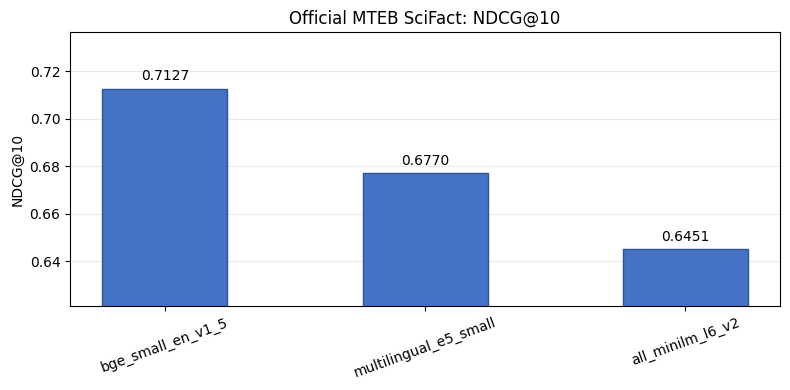

In [9]:
score_min = results["NDCG@10"].min()
score_max = results["NDCG@10"].max()
margin = max(0.02, (score_max - score_min) * 0.35)
y_min = max(0.0, score_min - margin)
y_max = min(1.0, score_max + margin)

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(
    results["model"],
    results["NDCG@10"],
    width=0.48,
    color="#4472c4",
    edgecolor="#2f5597",
)
ax.bar_label(bars, fmt="%.4f", padding=4)
ax.set_title("Official MTEB SciFact: NDCG@10")
ax.set_ylabel("NDCG@10")
ax.set_xlabel("")
ax.set_ylim(y_min, y_max)
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)
ax.tick_params(axis="x", rotation=20)
fig.tight_layout()


## Что именно измерено

- Метрики и qrels взяты из официальной задачи MTEB SciFact, без самописного пересчёта.
- Время включает загрузку модели из кэша, кодирование и retrieval внутри `mteb.evaluate`; это не latency готового ANN-индекса.
- Для сравнения Annoy, FAISS и HNSW используйте `vector_search.ipynb`: там сохранены отдельные локальные матрицы и другой, расширенный train+test-протокол.